# Data Mining Using Python
#### _Author: *Cynthia Rattey*_

In [13]:
## Importing needed packages for data analysis and validation

import pandas as pd
from pandas.api.types import is_numeric_dtype
from pandas.plotting import parallel_coordinates
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 

In [3]:
# fetch dataset 
iris = fetch_ucirepo(id=53) 
  
# data (as pandas dataframes) 
X = iris.data.features 
y = iris.data.targets 
  
# metadata 
print(iris.metadata) 
  
# variable information 
print(iris.variables) 


{'uci_id': 53, 'name': 'Iris', 'repository_url': 'https://archive.ics.uci.edu/dataset/53/iris', 'data_url': 'https://archive.ics.uci.edu/static/public/53/data.csv', 'abstract': 'A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification methods.\n', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 150, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1936, 'last_updated': 'Tue Sep 12 2023', 'dataset_doi': '10.24432/C56C76', 'creators': ['R. A. Fisher'], 'intro_paper': {'ID': 191, 'type': 'NATIVE', 'title': 'The Iris data set: In search of the source of virginica', 'authors': 'A. Unwin, K. Kleinman', 'venue': 'Significance, 2021', 'year': 2021, 'journal': 'Significance, 2021', 'DOI': '1740-9713.01589', 'URL': 'https://www.semanticscholar.org

In [4]:
# Saving data to a variable
data = pd.read_csv('https://archive.ics.uci.edu/static/public/53/data.csv')

data.head()

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
data.columns = ['sepal length', 'sepal width', 'petal length', 'petal width', 'class']

data.head(5)

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
# looping around to print Mean, Standard Deviation, Minimum and Maximum percentages

for col in data.columns:
    if is_numeric_dtype(data[col]):
        print('%s:' % (col))
        print('\t Mean = %.2f' % data[col].mean())
        print('\t Standard Deviation = %.2f' % data[col].std())
        print('\t Minimum = %.2f' % data[col].min())
        print('\t Maximum = %.2f' % data[col].max())

sepal length:
	 Mean = 5.84
	 Standard deviation = 0.83
	 Minimum = 4.30
	 Maximum = 7.90
sepal width:
	 Mean = 3.05
	 Standard deviation = 0.43
	 Minimum = 2.00
	 Maximum = 4.40
petal length:
	 Mean = 3.76
	 Standard deviation = 1.76
	 Minimum = 1.00
	 Maximum = 6.90
petal width:
	 Mean = 1.20
	 Standard deviation = 0.76
	 Minimum = 0.10
	 Maximum = 2.50


In [7]:
# Giving a number to the categorical column "Class"

data['class'].value_counts()

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [8]:
# Using the describe function 

data.describe(include = 'all')

,sepal length,sepal width,petal length,petal width,class
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.054000,3.758667,1.198667,NaN
std,0.828066,0.433594,1.764420,0.763161,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


In [9]:
# Pulling information about our data set

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal length  150 non-null    float64
 1   sepal width   150 non-null    float64
 2   petal length  150 non-null    float64
 3   petal width   150 non-null    float64
 4   class         150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [10]:
# investigating how 2 continuous variables change eachother

print('Covariance: ')
cov_matrix = data.cov(numeric_only = True)
cov_matrix

Covariance: 


,sepal length,sepal width,petal length,petal width
sepal length,0.685694,-0.039268,1.273682,0.516904
sepal width,-0.039268,0.188004,-0.321713,-0.117981
petal length,1.273682,-0.321713,3.113179,1.296387
petal width,0.516904,-0.117981,1.296387,0.582414


In [11]:
# Measuring the Correlation

print('Correlation: ')

corr_matrix = data.corr(numeric_only = True)

corr_matrix

Correlation: 


,sepal length,sepal width,petal length,petal width
sepal length,1.000000,-0.109369,0.871754,0.817954
sepal width,-0.109369,1.000000,-0.420516,-0.356544
petal length,0.871754,-0.420516,1.000000,0.962757
petal width,0.817954,-0.356544,0.962757,1.000000


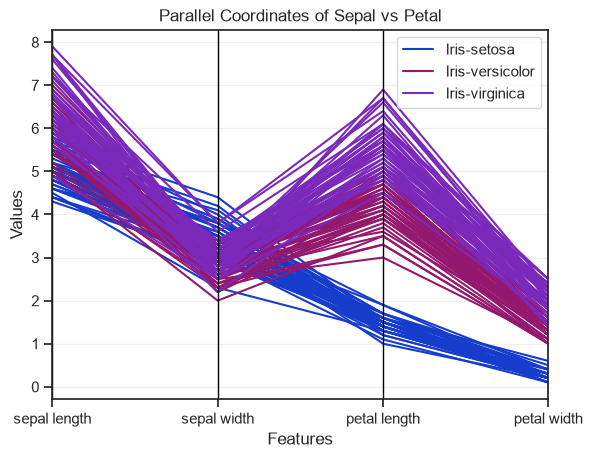

In [64]:
# looking for clusters

parallel_coordinates(data, 'class')

plt.title("Parallel Coordinates of Sepal vs Petal")
plt.xlabel("Features")
plt.ylabel("Values")
plt.grid(True, alpha = 0.3)
plt.show()

Text(0.5, 1.0, 'Petal vs Sepal Lengths')

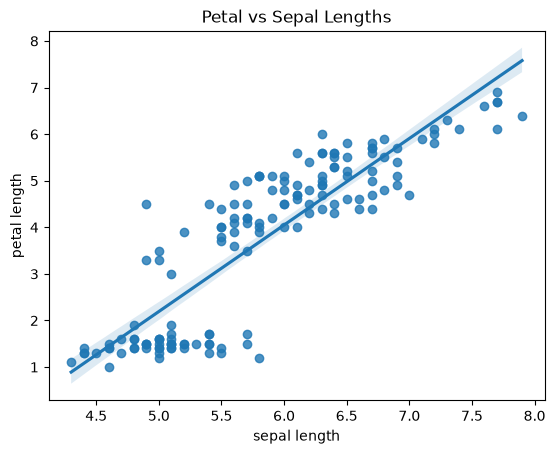

In [24]:
sns.regplot(x = 'sepal length', y = 'petal length', data = data)
plt.title("Petal vs Sepal Lengths")

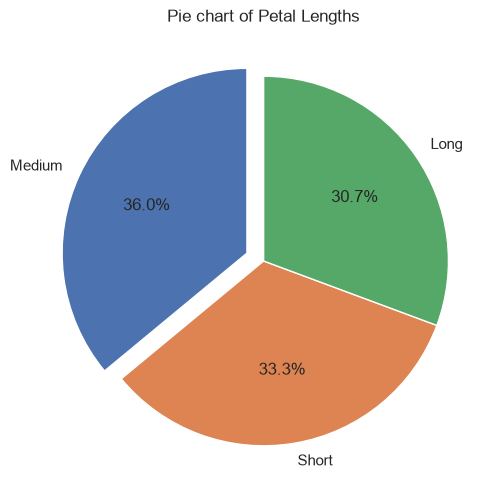

In [67]:
# Pie chart with pizazz
petal_bins = pd.cut(data['petal length'], bins = 3,  labels = ['Short', 'Medium', 'Long'])
petal_counts = petal_bins.value_counts()
explode = (0.1, 0, 0)

plt.figure(figsize = (6, 6))
plt.pie(
    petal_counts,
    labels = petal_counts.index,
    autopct = '%1.1f%%',
    explode = explode,
    startangle = 90
)

plt.title('Pie chart of Petal Lengths')
plt.show()

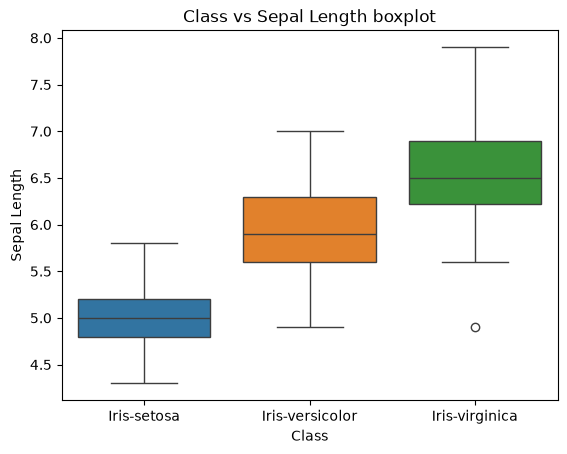

In [48]:
# Box plot

sns.boxplot(x = 'class', y = 'sepal length', data = data, hue = 'class' )
plt.xlabel('Class')
plt.ylabel('Sepal Length')
plt.title('Class vs Sepal Length boxplot')
plt.show()

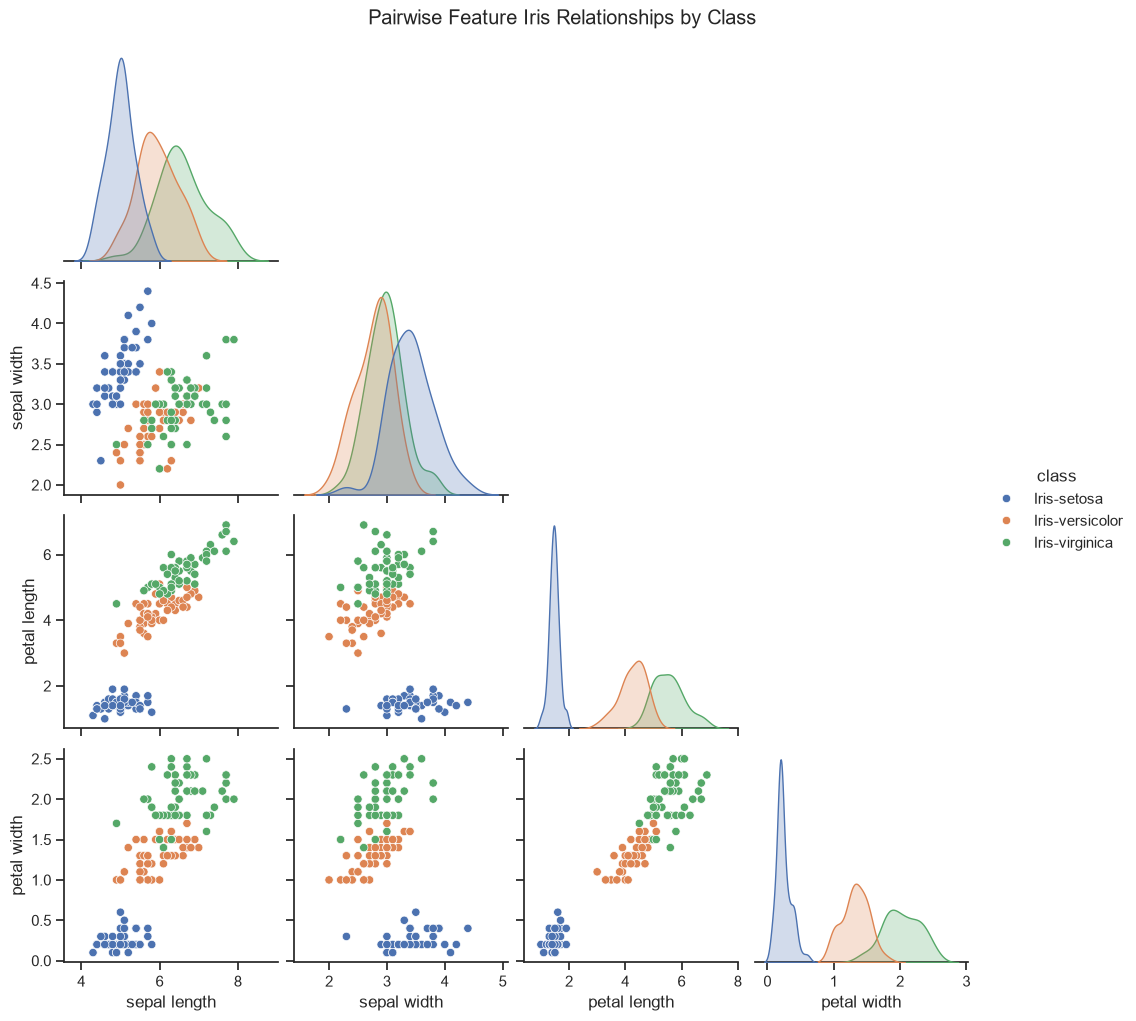

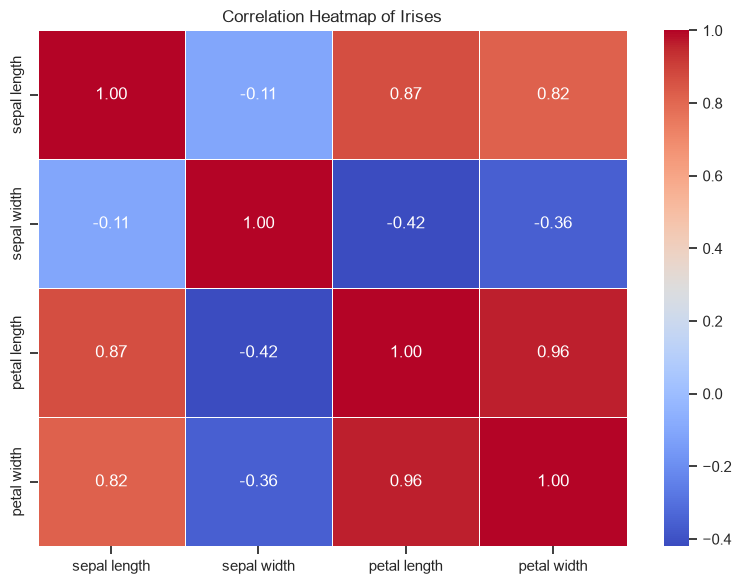

In [49]:
# Checking relations between all numerical variables with Pairplot or scatter matrix

sns.set_theme(style = "ticks")

pair_grid = sns.pairplot(
    data,
    hue = 'class',
    corner = True,
    diag_kind = 'kde',
)
pair_grid.fig.suptitle("Pairwise Feature Iris Relationships by Class", y = 1.02)
plt.show()

plt.figure(figsize = (8, 6))
numeric_data = data.select_dtypes(include = 'number')
sns.heatmap(
    numeric_data.corr(),
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
    linewidths = 0.5
)

plt.title("Correlation Heatmap of Irises")
plt.tight_layout()
plt.show()

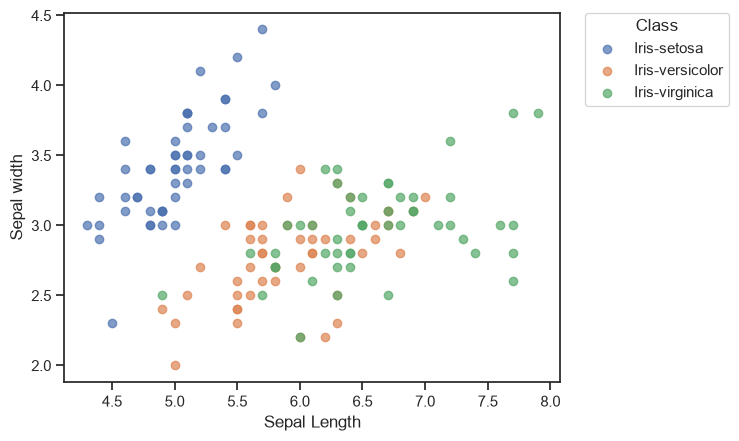

In [68]:
# Loopy for scatterplots

for class_name, group in data.groupby('class'):
    plt.scatter(
        group['sepal length'],
        group['sepal width'],
        label = class_name,
        alpha = 0.7
    )

plt.legend(title = 'Class', bbox_to_anchor = (1.05, 1), loc = 'upper left', borderaxespad=0)
plt.xlabel('Sepal Length')
plt.ylabel('Sepal width')
plt.show()